### 01. Import Libraries and Prepare Data

In [1]:
import numpy as np
import pandas as pd
import re
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

#  Download and load the dataset
file_paths = [
    "C:/Users/MAC/Videos/sentiment+labelled+sentences/amazon_cells_labelled.txt",
    "C:/Users/MAC/Videos/sentiment+labelled+sentences/imdb_labelled.txt",
    "C:/Users/MAC/Videos/sentiment+labelled+sentences/yelp_labelled.txt"
]

dataframes = []
for file in file_paths:
    # The dataset files are tab-separated with no headers
    df = pd.read_csv(file, sep='\t', header=None, names=['text', 'label'])
    dataframes.append(df)

# Combine all datasets into one
df = pd.concat(dataframes, ignore_index=True)
print(f"Total dataset shape: {df.shape}")


Total dataset shape: (2748, 2)


### 02. Text Preprocessing

In [2]:
#  Perform basic text preprocessing
def clean_text(text):
    # Convert text to lowercase
    text = text.lower()
    # Remove unnecessary characters and punctuation
    text = re.sub(r'[^\w\s]', '', text)
    # Remove extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# Create a clean-text column
df['clean_text'] = df['text'].apply(clean_text)

# Compare original and preprocessed text
display(df[['text', 'clean_text']].head())

,text,clean_text
0,So there is no way for me to plug it in here i...,so there is no way for me to plug it in here i...
1,"Good case, Excellent value.",good case excellent value
2,Great for the jawbone.,great for the jawbone
3,Tied to charger for conversations lasting more...,tied to charger for conversations lasting more...
4,The mic is great.,the mic is great


### 03. Explore the text data

In [3]:

# Display positive and negative examples
print("--- Positive Example ---")
print(df[df['label'] == 1]['text'].iloc[0])
print("\n--- Negative Example ---")
print(df[df['label'] == 0]['text'].iloc[0])

# Identify frequently occurring words
def get_frequent_words(text_series, top_n=10):
    all_words = ' '.join(text_series).split()
    return Counter(all_words).most_common(top_n)

pos_words = get_frequent_words(df[df['label'] == 1]['clean_text'])
neg_words = get_frequent_words(df[df['label'] == 0]['clean_text'])

print("\n--- Frequently Occurring Words ---")
print(f"Positive Reviews: {pos_words}")
print(f"Negative Reviews: {neg_words}")

# Observation: Stop words (the, and, is) dominate both lists.
# In a real-world scenario, you would remove these to isolate sentiment-heavy words (like 'great' or 'terrible').

--- Positive Example ---
Good case, Excellent value.

--- Negative Example ---
So there is no way for me to plug it in here in the US unless I go by a converter.

--- Frequently Occurring Words ---
Positive Reviews: [('the', 954), ('and', 661), ('a', 448), ('i', 411), ('is', 397), ('this', 316), ('it', 296), ('to', 286), ('of', 286), ('was', 248)]
Negative Reviews: [('the', 986), ('i', 476), ('and', 468), ('a', 438), ('to', 380), ('it', 369), ('is', 357), ('of', 335), ('this', 323), ('was', 322)]


### 04.  Splitting and Feature Extraction

In [4]:
X = df['clean_text']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining labels:")
print(y_train.value_counts())

print("\nTesting labels:")
print(y_test.value_counts())

Training samples: 2198
Testing samples: 550

Training labels:
label
1    1109
0    1089
Name: count, dtype: int64

Testing labels:
label
1    277
0    273
Name: count, dtype: int64


### 05.  Tokenization and Sequence Padding

In [5]:
import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding,
    LSTM,
    Dense,
    Dropout
)
from tensorflow.keras.callbacks import EarlyStopping


# Create tokenizer
tokenizer = Tokenizer(
    num_words=10000,
    oov_token="<OOV>"
)

# Learn vocabulary from training text
tokenizer.fit_on_texts(X_train)

# Convert training text into sequences
X_train_sequences = tokenizer.texts_to_sequences(X_train)

# Convert testing text into sequences
X_test_sequences = tokenizer.texts_to_sequences(X_test)

print("Example training sequence:")
print(X_train_sequences[0])

print("\nExample testing sequence:")
print(X_test_sequences[0])

Example training sequence:
[5, 110, 15, 163, 47, 9, 11, 1196, 1878, 1197, 1879, 24, 2, 1198, 2, 1199, 3, 1200, 10, 2, 132, 29, 54, 29, 100, 718, 190, 111, 1201, 2, 212, 1880, 885, 35, 1202, 4, 1203, 1881]

Example testing sequence:
[18, 1079, 50, 43, 1044]


### 06. Pad the Sequences

In [6]:
max_length = 100

X_train_padded = pad_sequences(
    X_train_sequences,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

X_test_padded = pad_sequences(
    X_test_sequences,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

print("Training shape:", X_train_padded.shape)
print("Testing shape:", X_test_padded.shape)

Training shape: (2198, 100)
Testing shape: (550, 100)


### 07. Check the Vocabulary Size

In [7]:
vocab_size = min(
    10000,
    len(tokenizer.word_index) + 1)

print("Vocabulary size:", vocab_size)


Vocabulary size: 4712


### 08. Build the LSTM Neural Network

In [10]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Embedding,
    LSTM,
    Bidirectional,
    Dense,
    Dropout
)

model = Sequential([
    Input(shape=(max_length,)),
    Embedding(
        input_dim=vocab_size,
        output_dim=128,
        mask_zero=True
    ),

    Bidirectional(LSTM(64)),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 100, 128)       │       603,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 706,113 (2.69 MB)

 Trainable params: 706,113 (2.69 MB)

 Non-trainable params: 0 (0.00 B)

### 09. Compile the Model

In [11]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

### 10. Create Early Stopping

In [12]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

### 11. Train the Neural Network

In [13]:
history = model.fit(
    X_train_padded,
    y_train,
    epochs=15,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/15
55/55 ━━━━━━━━━━━━━━━━━━━━ 9s 57ms/step - accuracy: 0.6263 - loss: 0.6739 - val_accuracy: 0.7727 - val_loss: 0.5742
Epoch 2/15
55/55 ━━━━━━━━━━━━━━━━━━━━ 3s 46ms/step - accuracy: 0.8623 - loss: 0.3994 - val_accuracy: 0.8364 - val_loss: 0.4139
Epoch 3/15
55/55 ━━━━━━━━━━━━━━━━━━━━ 3s 52ms/step - accuracy: 0.9579 - loss: 0.1456 - val_accuracy: 0.8386 - val_loss: 0.4587
Epoch 4/15
55/55 ━━━━━━━━━━━━━━━━━━━━ 3s 54ms/step - accuracy: 0.9812 - loss: 0.0727 - val_accuracy: 0.8182 - val_loss: 0.6015
Epoch 5/15
55/55 ━━━━━━━━━━━━━━━━━━━━ 3s 53ms/step - accuracy: 0.9892 - loss: 0.0579 - val_accuracy: 0.8250 - val_loss: 0.5847


### 12. Evaluate the Model on Test Data

In [14]:
test_loss, test_accuracy = model.evaluate(
    X_test_padded,
    y_test,
    verbose=0
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

Test Loss: 0.45119351148605347
Test Accuracy: 0.8054545521736145


### 13. Generate Test Predictions

In [16]:
y_probability = model.predict(
    X_test_padded,
    verbose=0
).ravel()

y_pred = (y_probability >= 0.5).astype(int)

print("Actual labels:")
print(Counter(y_test))

print("\nPredicted labels:")
print(Counter(y_pred))

Actual labels:
Counter({1: 277, 0: 273})

Predicted labels:
Counter({np.int64(1): 284, np.int64(0): 266})


### 14. Calculate Accuracy, Precision, Recall and F1

In [17]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("--- LSTM Neural Network Performance ---")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

--- LSTM Neural Network Performance ---
Accuracy:  0.8055
Precision: 0.7993
Recall:    0.8195
F1 Score:  0.8093


### 15. Classification Report

In [18]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred,
        target_names=['Negative', 'Positive']
    )
)

              precision    recall  f1-score   support

    Negative       0.81      0.79      0.80       273
    Positive       0.80      0.82      0.81       277

    accuracy                           0.81       550
   macro avg       0.81      0.81      0.81       550
weighted avg       0.81      0.81      0.81       550



### 16. Confusion Matrix

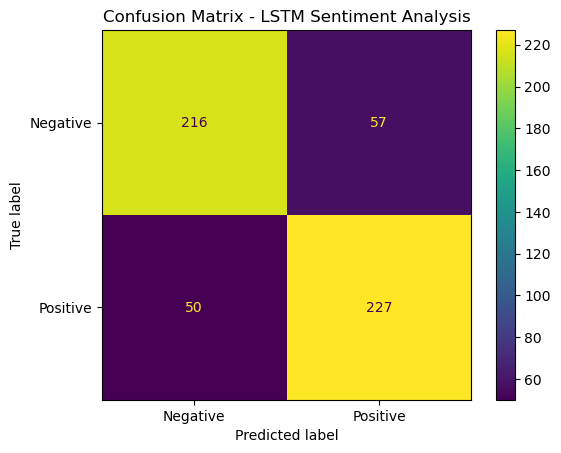

In [19]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Negative', 'Positive']
)

disp.plot()

plt.title("Confusion Matrix - LSTM Sentiment Analysis")
plt.show()

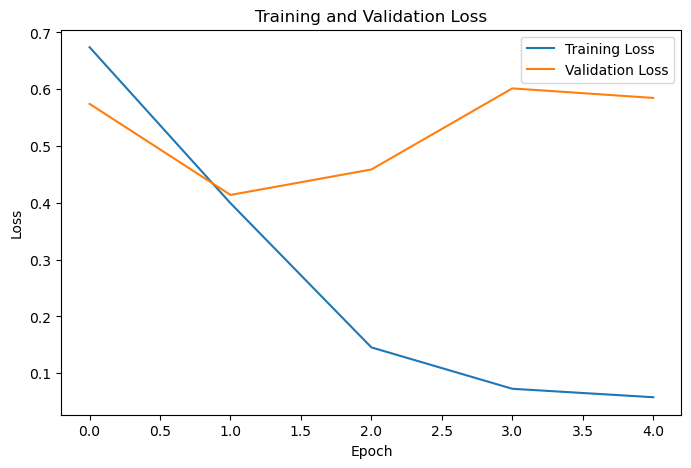

In [20]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()

plt.show()

In [21]:
def predict_sentiment(text):

    cleaned = clean_text(text)

    sequence = tokenizer.texts_to_sequences([cleaned])

    padded = pad_sequences(
        sequence,
        maxlen=max_length,
        padding='post',
        truncating='post'
    )

    probability = model.predict(
        padded,
        verbose=0
    )[0][0]

    sentiment = (
        "Positive"
        if probability >= 0.5
        else "Negative"
    )

    print("Text:", text)
    print("Sentiment:", sentiment)
    print("Positive Probability:", round(float(probability), 4))

In [23]:
predict_sentiment(
    "This movie was excellent and I really enjoyed it."
)

predict_sentiment(
    "This movie was terrible and I hated it."
)

predict_sentiment(
    "The movie was boring, disappointing, and a complete waste of time."
)
predict_sentiment(
    "The story was amazing and the actors performed very well."
)

Text: This movie was excellent and I really enjoyed it.
Sentiment: Positive
Positive Probability: 0.9964
Text: This movie was terrible and I hated it.
Sentiment: Negative
Positive Probability: 0.2567
Text: The movie was boring, disappointing, and a complete waste of time.
Sentiment: Negative
Positive Probability: 0.0176
Text: The story was amazing and the actors performed very well.
Sentiment: Positive
Positive Probability: 0.9584
